# Учимся работе с данными - от загрузки до моделирования

## Часть 1. EDA

### 1–2. Загрузка датасета и базовые статистики

In [3]:
import pandas as pd

# Датасет Breast Cancer Wisconsin (Diagnostic):
# https://www.kaggle.com/uciml/breast-cancer-wisconsin-data
df = pd.read_csv("data.csv")
df.head()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


In [4]:
df.shape

(569, 33)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    str    
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se             569 non-null

In [6]:
# Пустая колонка из исходного CSV на Kaggle — удаляем
df = df.drop(columns=["Unnamed: 32", "id"])

df["diagnosis"].value_counts()

diagnosis
B    357
M    212
Name: count, dtype: int64

In [7]:
# Базовые статистики: mean, std, min, квартили (медиана = 50%), max
df.describe().T

,count,mean,std,min,25%,50%,75%,max
radius_mean,569.0,14.127292,3.524049,6.981000,11.700000,13.370000,15.780000,28.11000
texture_mean,569.0,19.289649,4.301036,9.710000,16.170000,18.840000,21.800000,39.28000
perimeter_mean,569.0,91.969033,24.298981,43.790000,75.170000,86.240000,104.100000,188.50000
area_mean,569.0,654.889104,351.914129,143.500000,420.300000,551.100000,782.700000,2501.00000
smoothness_mean,569.0,0.096360,0.014064,0.052630,0.086370,0.095870,0.105300,0.16340
compactness_mean,569.0,0.104341,0.052813,0.019380,0.064920,0.092630,0.130400,0.34540
concavity_mean,569.0,0.088799,0.079720,0.000000,0.029560,0.061540,0.130700,0.42680
concave points_mean,569.0,0.048919,0.038803,0.000000,0.020310,0.033500,0.074000,0.20120
symmetry_mean,569.0,0.181162,0.027414,0.106000,0.161900,0.179200,0.195700,0.30400
fractal_dimension_mean,569.0,0.062798,0.007060,0.049960,0.057700,0.061540,0.066120,0.09744


In [8]:
# Статистики по классам целевой переменной (B — benign, M — malignant)
df.groupby("diagnosis").agg(["mean", "median", "std"]).T

diagnosis                               B          M
radius_mean             mean    12.146524  17.462830
                        median  12.200000  17.325000
                        std      1.780512   3.203971
texture_mean            mean    17.914762  21.604906
                        median  17.390000  21.460000
...                                   ...        ...
symmetry_worst          median   0.268700   0.310300
                        std      0.041745   0.074685
fractal_dimension_worst mean     0.079442   0.091530
                        median   0.077120   0.087600
                        std      0.013804   0.021553

[90 rows x 2 columns]

### 3. Гистограммы признаков с группировкой по целевой переменной

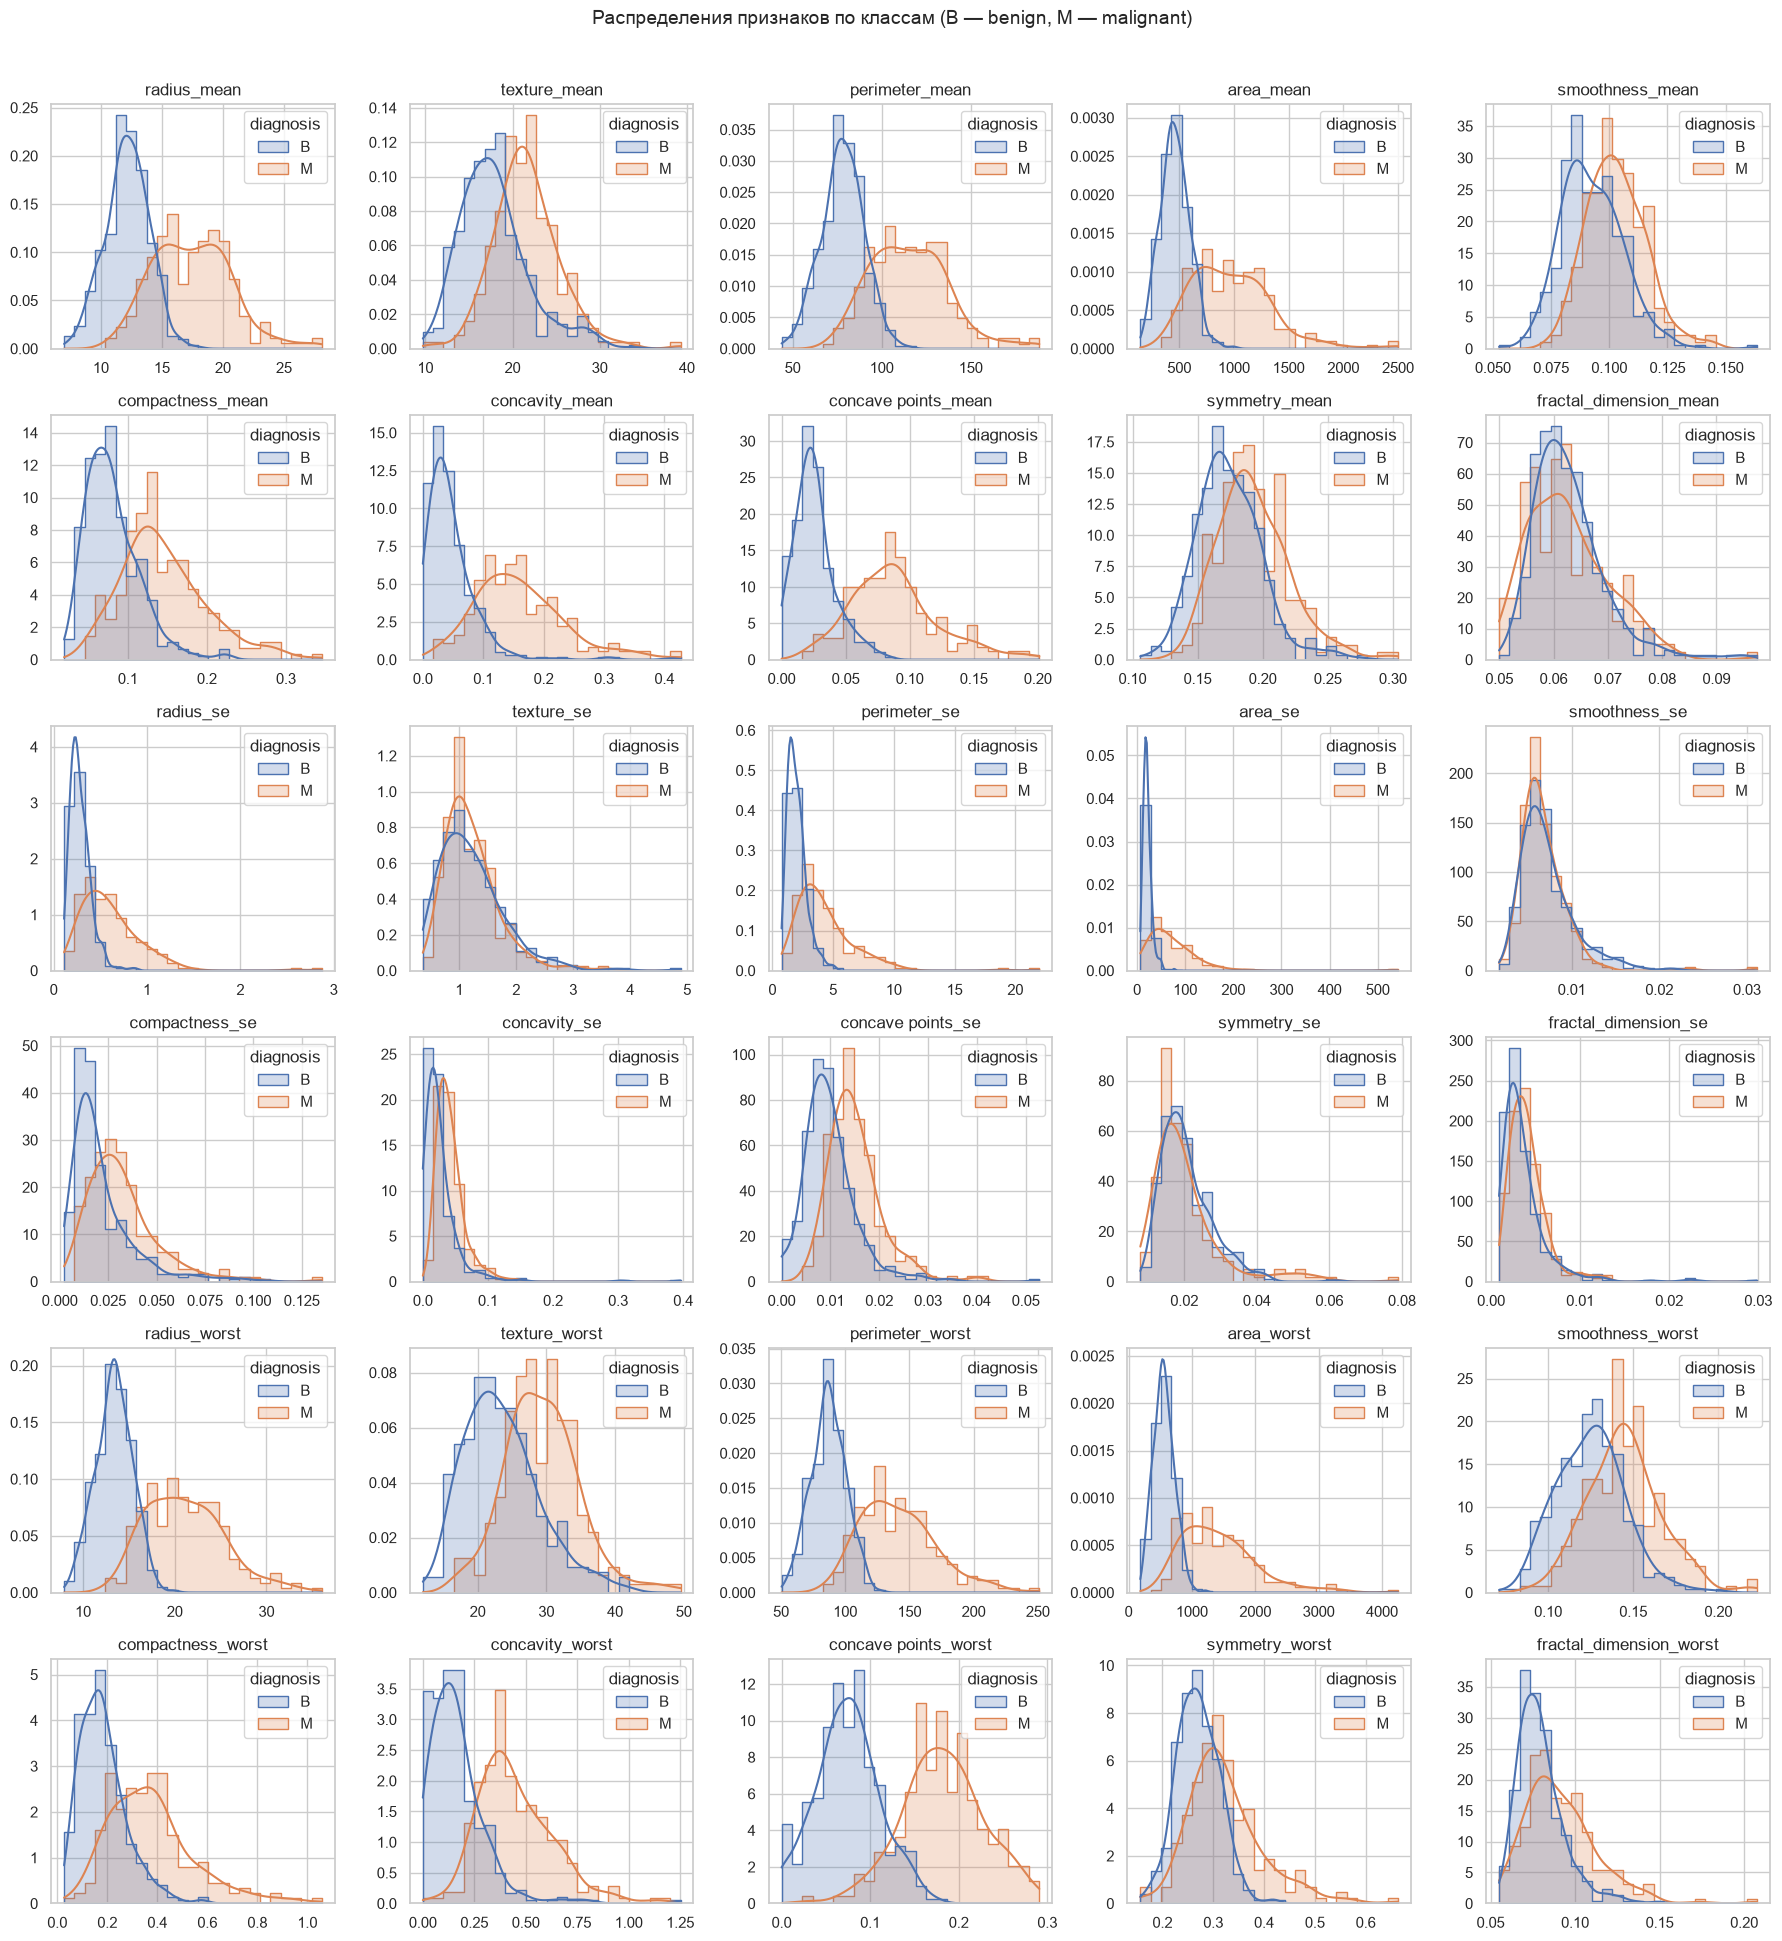

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

features = df.columns.drop("diagnosis")
n_cols = 5
n_rows = (len(features) + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 3.2 * n_rows))
axes = axes.ravel()

for ax, col in zip(axes, features):
    sns.histplot(
        data=df,
        x=col,
        hue="diagnosis",
        hue_order=["B", "M"],
        palette={"B": "#4C72B0", "M": "#DD8452"},
        bins=25,
        kde=True,
        element="step",
        stat="density",
        common_norm=False,
        ax=ax,
    )
    ax.set_title(col)
    ax.set_xlabel("")
    ax.set_ylabel("")

for ax in axes[len(features):]:
    ax.set_visible(False)

fig.suptitle("Распределения признаков по классам (B — benign, M — malignant)", y=1.01, fontsize=14)
plt.tight_layout()
plt.show()

### 4. Heatmap матрицы корреляций

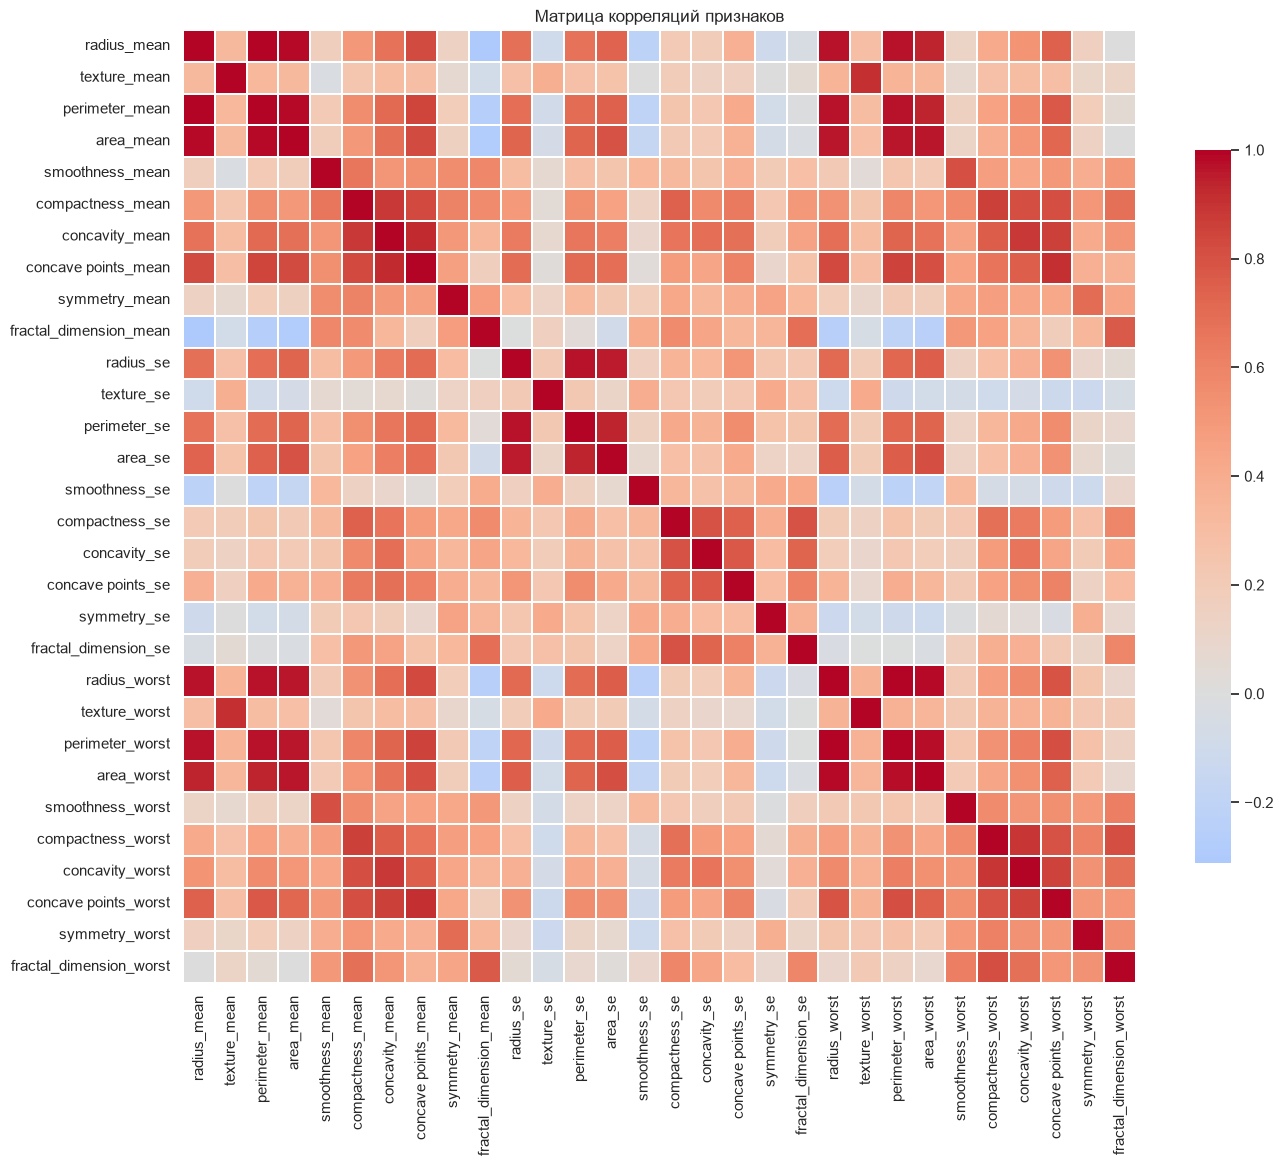

In [10]:
corr = df.drop(columns=["diagnosis"]).corr()

plt.figure(figsize=(14, 12))
sns.heatmap(
    corr,
    cmap="coolwarm",
    center=0,
    square=True,
    linewidths=0.3,
    cbar_kws={"shrink": 0.7},
)
plt.title("Матрица корреляций признаков")
plt.tight_layout()
plt.show()

In [11]:
import numpy as np

# Пары с сильной корреляцией (|r| >= 0.9)
strong_pairs = (
    corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
    .stack()
    .rename("corr")
    .reset_index()
    .rename(columns={"level_0": "feature_1", "level_1": "feature_2"})
)
strong_pairs = strong_pairs.loc[strong_pairs["corr"].abs() >= 0.9].sort_values(
    "corr", key=abs, ascending=False
)
strong_pairs

,feature_1,feature_2,corr
2,radius_mean,perimeter_mean,0.997855
622,radius_worst,perimeter_worst,0.993708
3,radius_mean,area_mean,0.987357
63,perimeter_mean,area_mean,0.986507
623,radius_worst,area_worst,0.984015
683,perimeter_worst,area_worst,0.977578
312,radius_se,perimeter_se,0.972794
82,perimeter_mean,perimeter_worst,0.970387
20,radius_mean,radius_worst,0.969539
80,perimeter_mean,radius_worst,0.969476


**Вывод.** Да, есть сильно скоррелированные признаки (|r| ≥ 0.9):

1. **Размерные признаки внутри одной группы** (`_mean` / `_se` / `_worst`): `radius`, `perimeter`, `area` почти линейно связаны (геометрически связаны: площадь и периметр растут вместе с радиусом). Типичные пары: `radius_mean`–`perimeter_mean` (≈0.998), `radius_mean`–`area_mean` (≈0.987), то же для `_worst` и `_se`.
2. **Одни и те же признаки в разных агрегатах**: `radius_mean`–`radius_worst`, `perimeter_mean`–`perimeter_worst`, `area_mean`–`area_worst`, `texture_mean`–`texture_worst`.
3. **Форма контура**: `concavity_mean`–`concave points_mean`, `concave points_mean`–`concave points_worst`.

Это ожидаемо: часть колонок описывает один и тот же физический размер разными способами.

### 5. Scatterplot-ы для сильно скоррелированных признаков

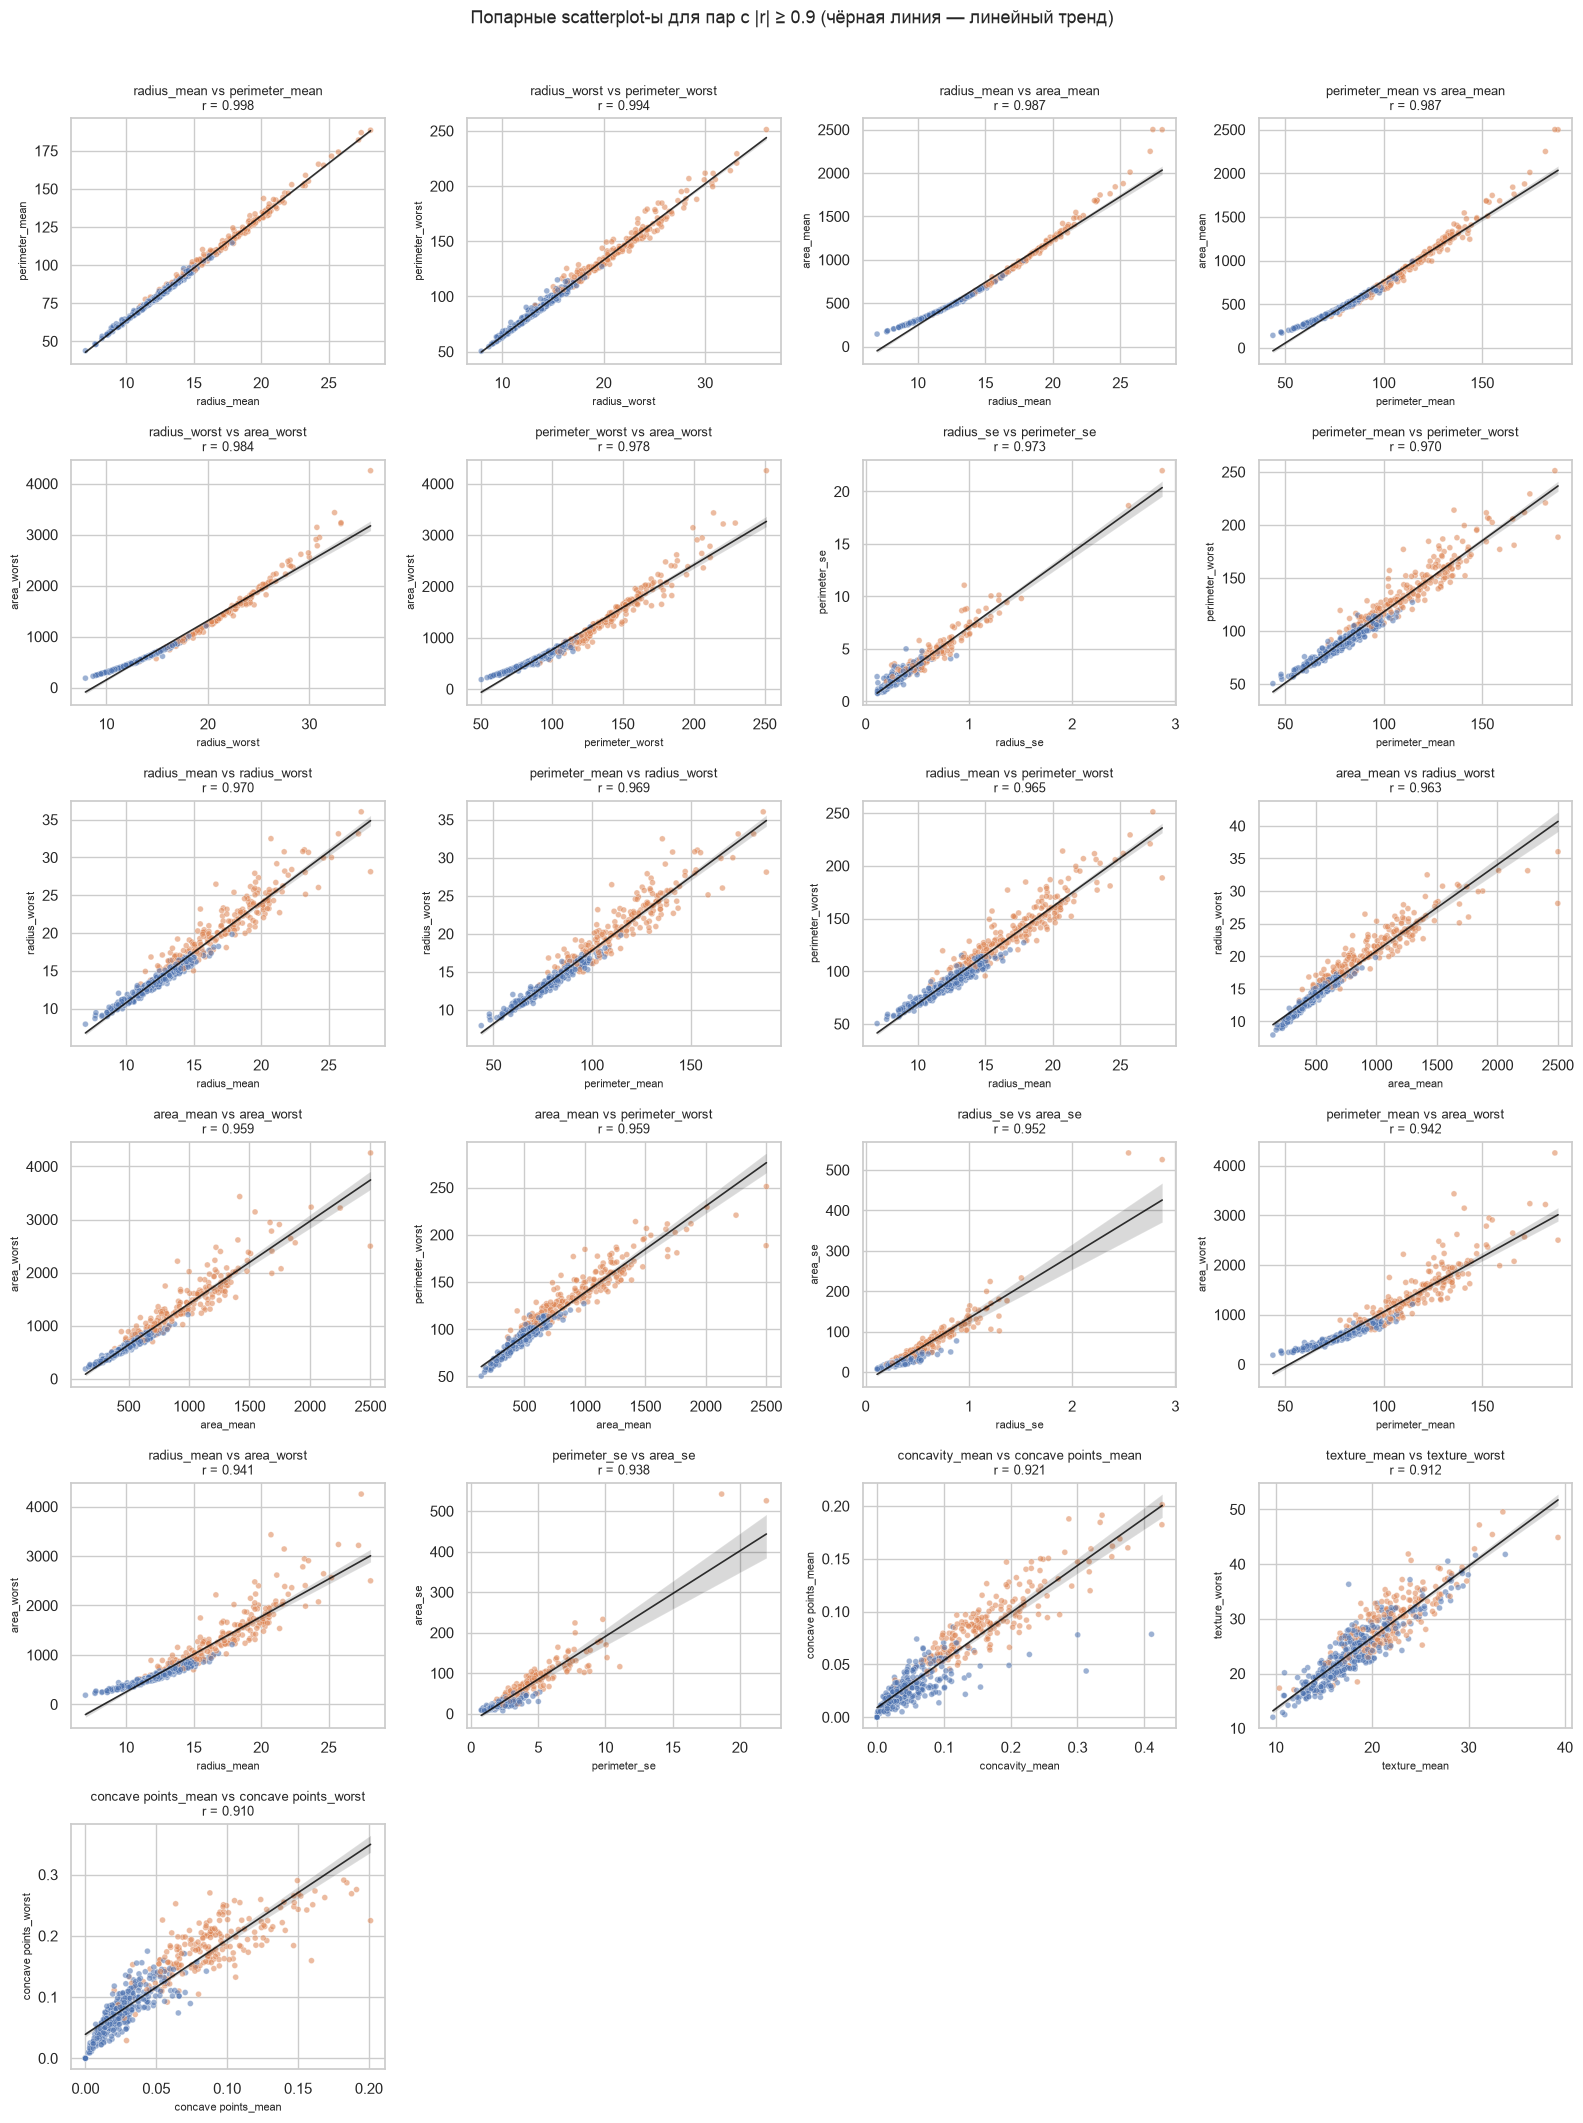

In [12]:
n_pairs = len(strong_pairs)
n_cols = 4
n_rows = (n_pairs + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 3.5 * n_rows))
axes = axes.ravel()

for ax, (_, row) in zip(axes, strong_pairs.iterrows()):
    x, y, r = row["feature_1"], row["feature_2"], row["corr"]
    sns.scatterplot(
        data=df,
        x=x,
        y=y,
        hue="diagnosis",
        hue_order=["B", "M"],
        palette={"B": "#4C72B0", "M": "#DD8452"},
        alpha=0.55,
        s=18,
        ax=ax,
        legend=False,
    )
    # линия тренда — визуально проверяем линейность
    sns.regplot(
        data=df,
        x=x,
        y=y,
        scatter=False,
        color="black",
        line_kws={"linewidth": 1.2, "alpha": 0.8},
        ax=ax,
    )
    ax.set_title(f"{x} vs {y}\nr = {r:.3f}", fontsize=9)
    ax.set_xlabel(x, fontsize=8)
    ax.set_ylabel(y, fontsize=8)

for ax in axes[n_pairs:]:
    ax.set_visible(False)

fig.suptitle(
    "Попарные scatterplot-ы для пар с |r| ≥ 0.9 (чёрная линия — линейный тренд)",
    y=1.01,
    fontsize=13,
)
plt.tight_layout()
plt.show()

**Вывод.** Да, линейная зависимость в целом наблюдается: точки выстраиваются вдоль прямой, особенно для `radius`–`perimeter`–`area` (и в `_mean`, и в `_worst`). Для `area` vs `radius` облако чуть изогнуто (площадь ~ радиус²), но в диапазоне данных всё равно близко к линейному тренду. Пары `concavity`–`concave points` тоже почти линейны, с чуть большим разбросом.

### 6. Boxplot-ы по целевой переменной: какие признаки лучше разделяют классы?

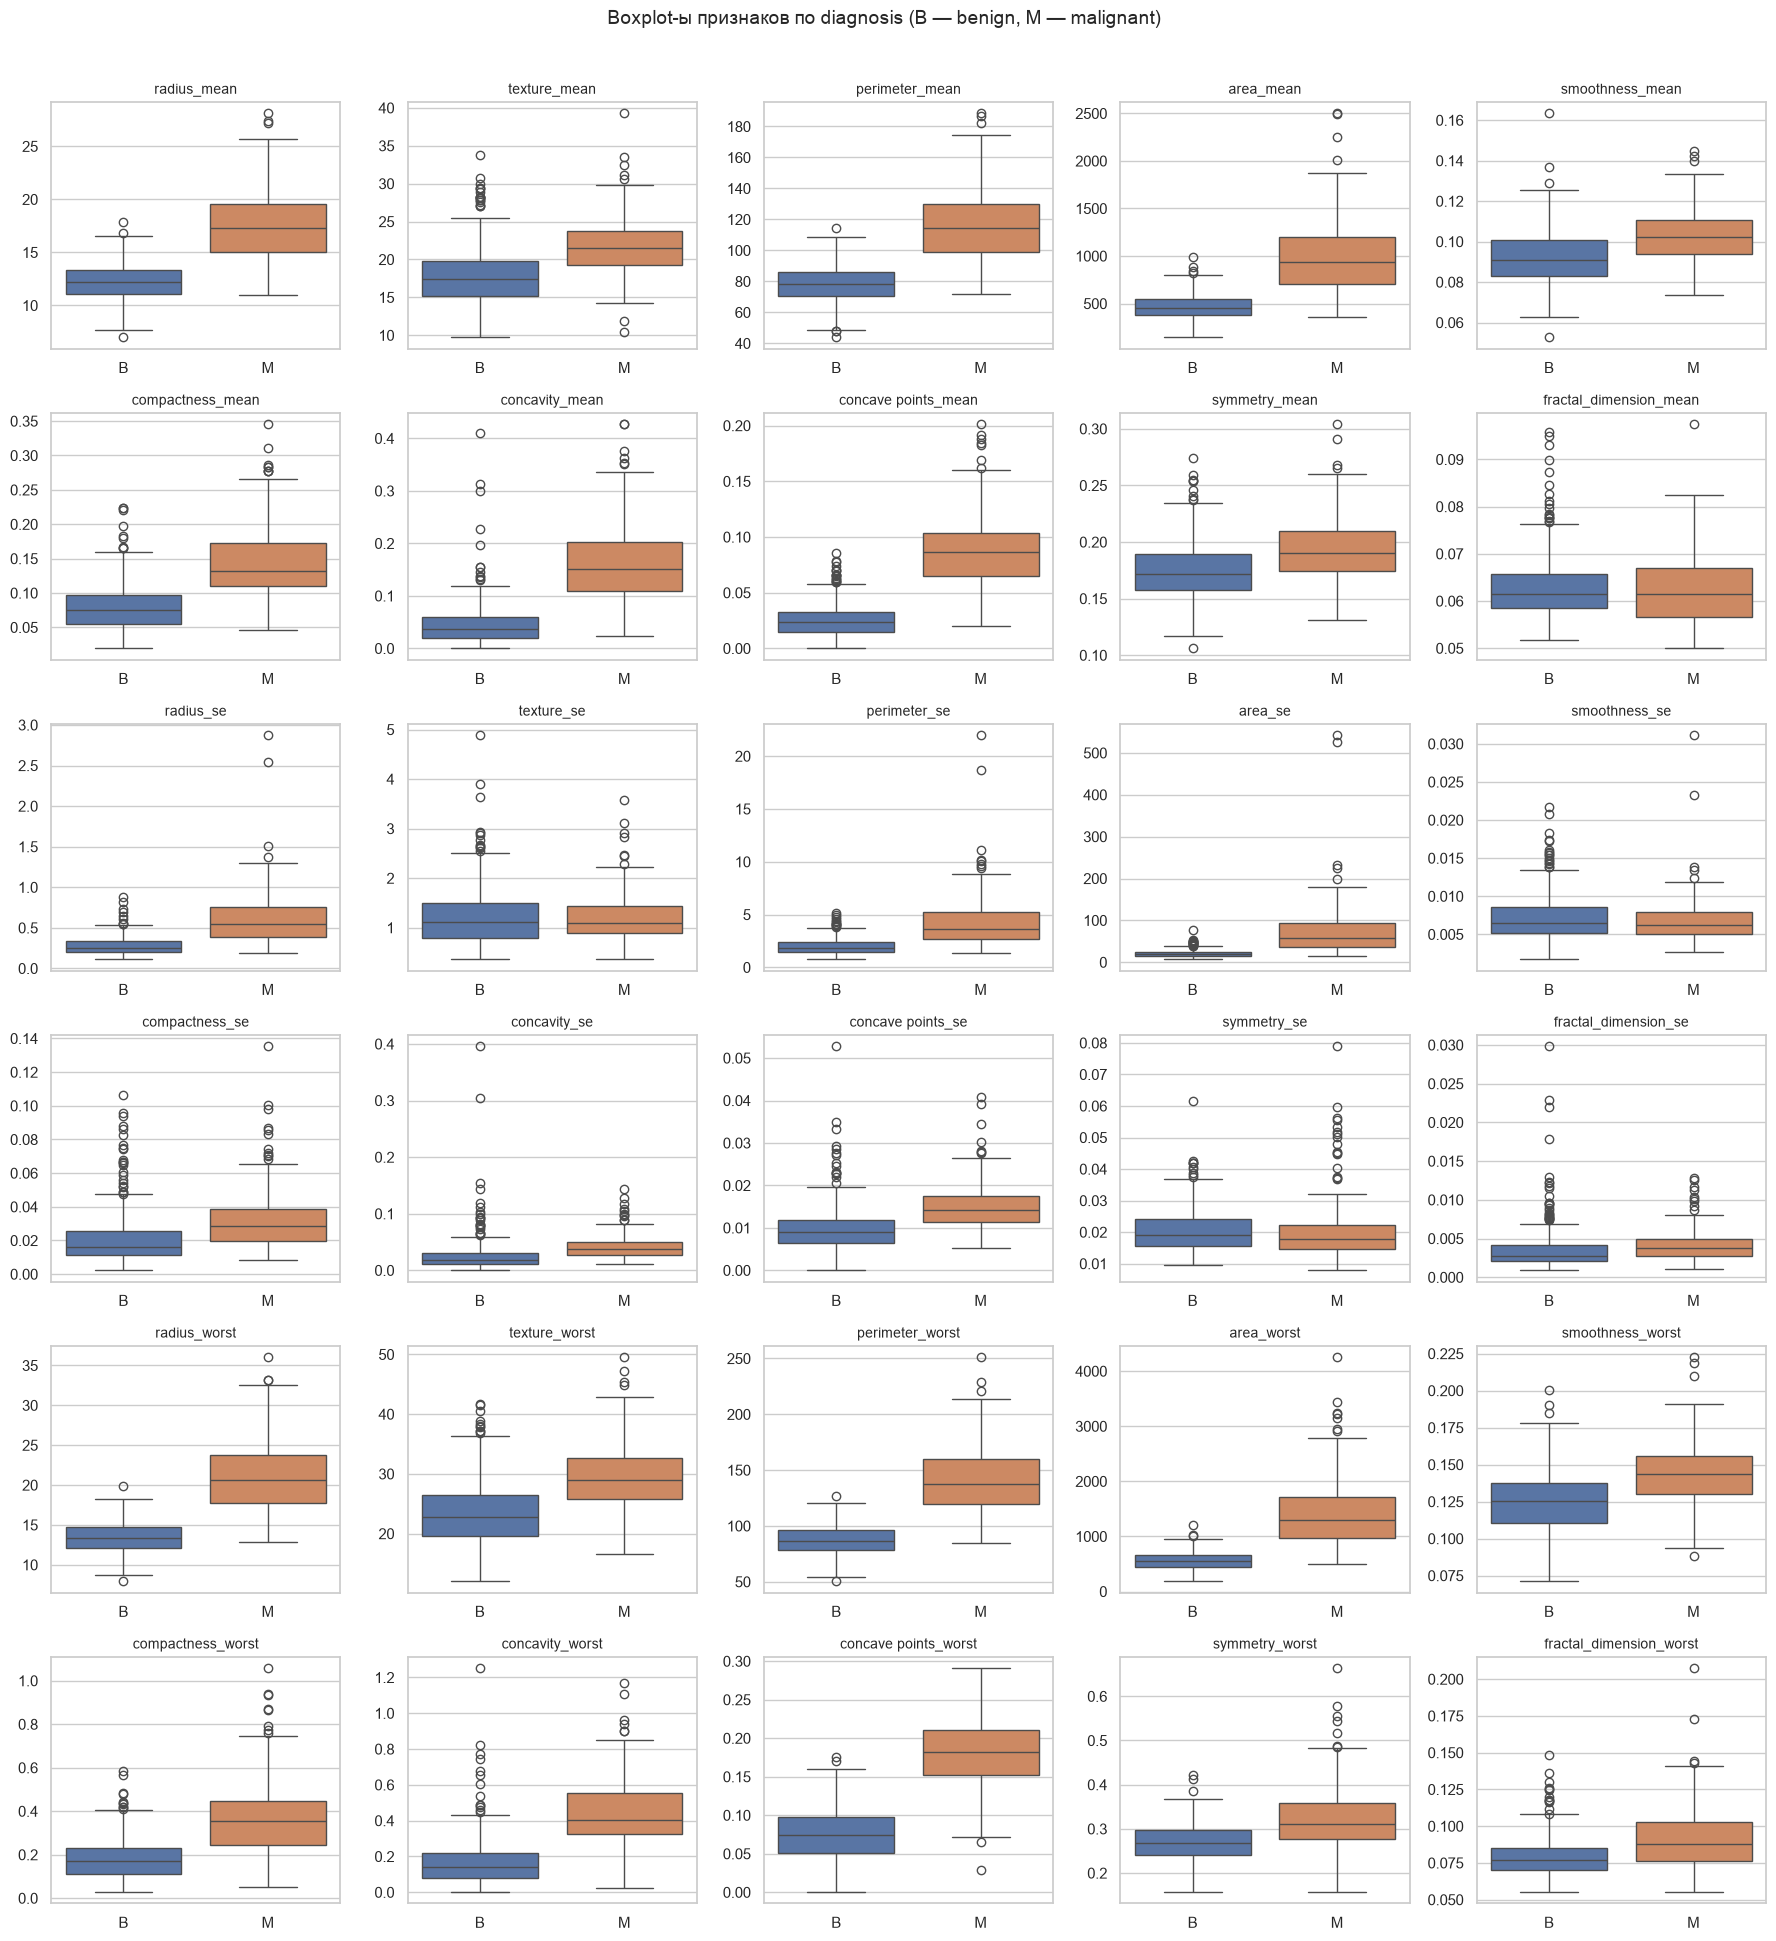

In [13]:
features = df.columns.drop("diagnosis")
n_cols = 5
n_rows = (len(features) + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 3.2 * n_rows))
axes = axes.ravel()

for ax, col in zip(axes, features):
    sns.boxplot(
        data=df,
        x="diagnosis",
        y=col,
        order=["B", "M"],
        hue="diagnosis",
        hue_order=["B", "M"],
        palette={"B": "#4C72B0", "M": "#DD8452"},
        legend=False,
        ax=ax,
    )
    ax.set_title(col, fontsize=10)
    ax.set_xlabel("")
    ax.set_ylabel("")

for ax in axes[len(features):]:
    ax.set_visible(False)

fig.suptitle(
    "Boxplot-ы признаков по diagnosis (B — benign, M — malignant)",
    y=1.01,
    fontsize=14,
)
plt.tight_layout()
plt.show()

In [14]:
# Насколько классы разнесены: |Cohen's d| = |mean_M - mean_B| / pooled_std
rows = []
for col in features:
    b = df.loc[df["diagnosis"] == "B", col]
    m = df.loc[df["diagnosis"] == "M", col]
    pooled = np.sqrt(((len(b) - 1) * b.var() + (len(m) - 1) * m.var()) / (len(b) + len(m) - 2))
    d = (m.mean() - b.mean()) / pooled if pooled else 0.0
    rows.append({"feature": col, "cohens_d": d, "abs_d": abs(d)})

separation = pd.DataFrame(rows).sort_values("abs_d", ascending=False)
separation.head(12)

,feature,cohens_d,abs_d
27,concave points_worst,2.692647,2.692647
22,perimeter_worst,2.598237,2.598237
7,concave points_mean,2.545225,2.545225
20,radius_worst,2.543903,2.543903
2,perimeter_mean,2.289516,2.289516
23,area_worst,2.230242,2.230242
0,radius_mean,2.205463,2.205463
3,area_mean,2.075651,2.075651
6,concavity_mean,2.003275,2.003275
26,concavity_worst,1.811931,1.811931


**Вывод.** Удобнее всего отделять M от B по признакам, у которых на boxplot медианы и «коробки» почти не пересекаются:

- **Лучшие разделители:** `concave points_worst`, `perimeter_worst`, `concave points_mean`, `radius_worst`, `perimeter_mean`, `area_worst`, `radius_mean`, `area_mean`, `concavity_mean` — у злокачественных значения заметно выше.
- **Слабые разделители:** `fractal_dimension_mean`, `texture_se`, `symmetry_se`, `smoothness_se` — распределения B и M почти совпадают.

Интуиция: злокачественные опухоли крупнее и с более неправильным/вогнутым контуром; именно размер (`radius`/`perimeter`/`area`, особенно `*_worst`) и вогнутость (`concave points`, `concavity`) дают наибольшее разделение.

## Часть 2. Моделирование при помощи kNN

### 1. Разбиение на train / test (30% на тест)

In [15]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=["diagnosis"])
# M (malignant) = 1, B (benign) = 0
y = (df["diagnosis"] == "M").astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.3,
    random_state=42,
    stratify=y,
)

print(f"Train: {X_train.shape[0]} объектов")
print(f"Test:  {X_test.shape[0]} объектов")
print("Доля M в train:", round(y_train.mean(), 3))
print("Доля M в test: ", round(y_test.mean(), 3))

Train: 398 объектов
Test:  171 объектов
Доля M в train: 0.372
Доля M в test:  0.374


### 2. Стандартизация признаков

In [16]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = pd.DataFrame(
    scaler.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index,
)
X_test_scaled = pd.DataFrame(
    scaler.transform(X_test),
    columns=X_test.columns,
    index=X_test.index,
)

# После стандартизации среднее ≈ 0, std ≈ 1 (считаем по train)
X_train_scaled.describe().loc[["mean", "std"]].T.head(10)

,mean,std
radius_mean,4.463208e-17,1.001259
texture_mean,-4.407418e-16,1.001259
perimeter_mean,7.933352e-16,1.001259
area_mean,5.355850e-17,1.001259
smoothness_mean,-1.640229e-16,1.001259
compactness_mean,-9.149577e-17,1.001259
concavity_mean,-1.272014e-16,1.001259
concave points_mean,-6.694812e-18,1.001259
symmetry_mean,1.544270e-15,1.001259
fractal_dimension_mean,1.376900e-15,1.001259


**Почему нужна стандартизация.** kNN считает расстояние между объектами (обычно евклидово). Признаки в разных шкалах: `area` — сотни/тысячи, `smoothness` — сотые доли. Без масштабирования расстояние почти полностью определяют крупномасштабные признаки, а мелкие почти не влияют. Стандартизация приводит все признаки к одному масштабу, чтобы вклад в расстояние был сопоставим.

### 3. kNN «из коробки» — метрики и ROC-кривая

In [17]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    classification_report,
)

knn = KNeighborsClassifier()  # n_neighbors=5 по умолчанию
knn.fit(X_train_scaled, y_train)

y_pred = knn.predict(X_test_scaled)
y_proba = knn.predict_proba(X_test_scaled)[:, 1]

metrics_default = {
    "accuracy": accuracy_score(y_test, y_pred),
    "precision": precision_score(y_test, y_pred),
    "recall": recall_score(y_test, y_pred),
    "f1_score": f1_score(y_test, y_pred),
    "roc_auc": roc_auc_score(y_test, y_proba),
}

print("Параметры модели:", knn.get_params())
print("\nМетрики на test:")
for name, value in metrics_default.items():
    print(f"  {name:10s}: {value:.4f}")
print("\n", classification_report(y_test, y_pred, target_names=["B (0)", "M (1)"]))

Параметры модели: {'algorithm': 'auto', 'leaf_size': 30, 'metric': 'minkowski', 'metric_params': None, 'n_jobs': None, 'n_neighbors': 5, 'p': 2, 'weights': 'uniform'}

Метрики на test:
  accuracy  : 0.9649
  precision : 1.0000
  recall    : 0.9062
  f1_score  : 0.9508
  roc_auc   : 0.9882

               precision    recall  f1-score   support

       B (0)       0.95      1.00      0.97       107
       M (1)       1.00      0.91      0.95        64

    accuracy                           0.96       171
   macro avg       0.97      0.95      0.96       171
weighted avg       0.97      0.96      0.96       171



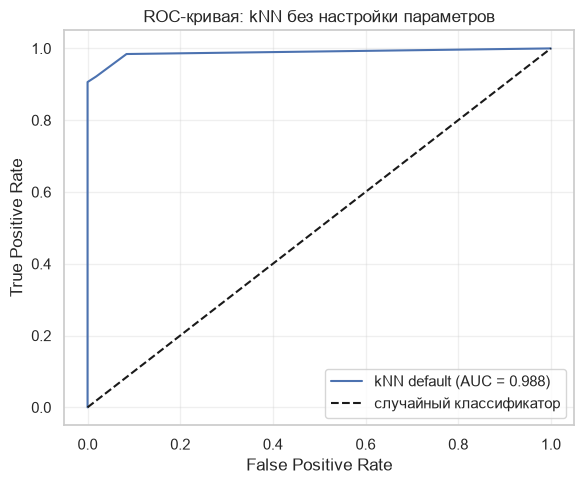

In [18]:
fpr, tpr, _ = roc_curve(y_test, y_proba)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f"kNN default (AUC = {metrics_default['roc_auc']:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="случайный классификатор")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC-кривая: kNN без настройки параметров")
plt.legend(loc="lower right")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### 4. Настройка числа соседей на кросс-валидации

In [19]:
from sklearn.model_selection import GridSearchCV

param_grid = {"n_neighbors": range(1, 31)}
grid_knn = GridSearchCV(
    KNeighborsClassifier(),
    param_grid,
    cv=5,
    scoring="f1",
    return_train_score=True,
)
grid_knn.fit(X_train_scaled, y_train)

print("Лучший n_neighbors:", grid_knn.best_params_["n_neighbors"])
print("CV F1 (best):", round(grid_knn.best_score_, 4))

Лучший n_neighbors: 5
CV F1 (best): 0.9564


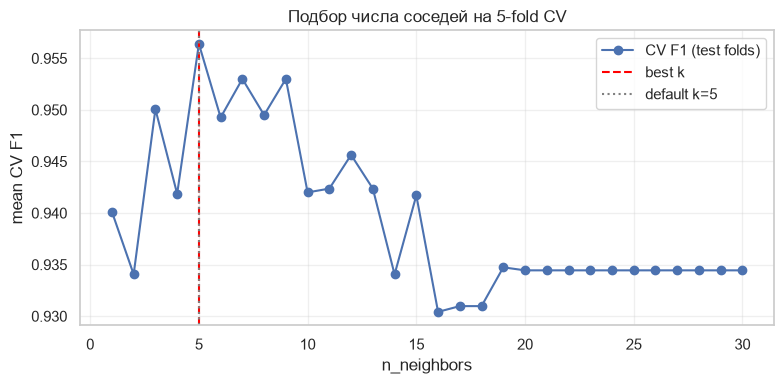

In [20]:
cv_results = pd.DataFrame(grid_knn.cv_results_)

plt.figure(figsize=(8, 4))
plt.plot(cv_results["param_n_neighbors"], cv_results["mean_test_score"], marker="o", label="CV F1 (test folds)")
plt.axvline(grid_knn.best_params_["n_neighbors"], color="red", linestyle="--", label="best k")
plt.axvline(5, color="gray", linestyle=":", label="default k=5")
plt.xlabel("n_neighbors")
plt.ylabel("mean CV F1")
plt.title("Подбор числа соседей на 5-fold CV")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [21]:
knn_tuned = grid_knn.best_estimator_
y_pred_tuned = knn_tuned.predict(X_test_scaled)
y_proba_tuned = knn_tuned.predict_proba(X_test_scaled)[:, 1]

metrics_tuned = {
    "accuracy": accuracy_score(y_test, y_pred_tuned),
    "precision": precision_score(y_test, y_pred_tuned),
    "recall": recall_score(y_test, y_pred_tuned),
    "f1_score": f1_score(y_test, y_pred_tuned),
    "roc_auc": roc_auc_score(y_test, y_proba_tuned),
}

comparison = pd.DataFrame(
    {"kNN default (k=5)": metrics_default, "kNN tuned": metrics_tuned}
).T
comparison.round(4)

,accuracy,precision,recall,f1_score,roc_auc
kNN default (k=5),0.9649,1.0,0.9062,0.9508,0.9882
kNN tuned,0.9649,1.0,0.9062,0.9508,0.9882


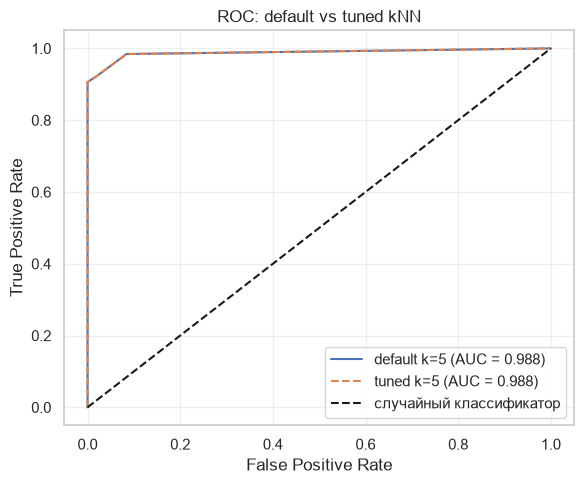

In [22]:
fpr_t, tpr_t, _ = roc_curve(y_test, y_proba_tuned)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f"default k=5 (AUC = {metrics_default['roc_auc']:.3f})")
plt.plot(
    fpr_t,
    tpr_t,
    linestyle="--",
    label=f"tuned k={knn_tuned.n_neighbors} (AUC = {metrics_tuned['roc_auc']:.3f})",
)
plt.plot([0, 1], [0, 1], "k--", label="случайный классификатор")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC: default vs tuned kNN")
plt.legend(loc="lower right")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

**Стало ли лучше?** На 5-fold CV по F1 оптимальный `n_neighbors` оказался равен **5** — то есть совпал с дефолтом «из коробки». Метрики на test поэтому те же (accuracy ≈ 0.96, F1 ≈ 0.95, AUC ≈ 0.99). Подбор подтвердил, что baseline уже был хорош; заметного выигрыша нет.

## Бонус. Логистическая регрессия

### 1. Удаление сильно скоррелированных признаков (|r| > 0.85)

In [23]:
# Ищем пары с |corr| > 0.85 и оставляем по одному признаку из каждой связки
# (из верхней треугольной части матрицы удаляем второй признак пары)
corr_abs = X_train.corr().abs()
upper = corr_abs.where(np.triu(np.ones(corr_abs.shape), k=1).astype(bool))

to_drop = [col for col in upper.columns if any(upper[col] > 0.85)]
features_lr = [col for col in X_train.columns if col not in to_drop]

print(f"Было признаков: {X_train.shape[1]}")
print(f"Удалено (|r| > 0.85): {len(to_drop)}")
print("Удалённые:", to_drop)
print(f"\nОсталось: {len(features_lr)}")
print("Оставшиеся:", features_lr)

X_train_lr = X_train_scaled[features_lr]
X_test_lr = X_test_scaled[features_lr]

Было признаков: 30
Удалено (|r| > 0.85): 13
Удалённые: ['perimeter_mean', 'area_mean', 'concavity_mean', 'concave points_mean', 'perimeter_se', 'area_se', 'radius_worst', 'texture_worst', 'perimeter_worst', 'area_worst', 'compactness_worst', 'concavity_worst', 'concave points_worst']

Осталось: 17
Оставшиеся: ['radius_mean', 'texture_mean', 'smoothness_mean', 'compactness_mean', 'symmetry_mean', 'fractal_dimension_mean', 'radius_se', 'texture_se', 'smoothness_se', 'compactness_se', 'concavity_se', 'concave points_se', 'symmetry_se', 'fractal_dimension_se', 'smoothness_worst', 'symmetry_worst', 'fractal_dimension_worst']


### 2. Логистическая регрессия «из коробки» — метрики, ROC и коэффициенты

In [24]:
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression(random_state=42)  # C=1.0 по умолчанию
lr.fit(X_train_lr, y_train)

y_pred_lr = lr.predict(X_test_lr)
y_proba_lr = lr.predict_proba(X_test_lr)[:, 1]

metrics_lr = {
    "accuracy": accuracy_score(y_test, y_pred_lr),
    "precision": precision_score(y_test, y_pred_lr),
    "recall": recall_score(y_test, y_pred_lr),
    "f1_score": f1_score(y_test, y_pred_lr),
    "roc_auc": roc_auc_score(y_test, y_proba_lr),
}

print("Параметры модели:", {k: lr.get_params()[k] for k in ["C", "penalty", "solver"]})
print("\nМетрики на test:")
for name, value in metrics_lr.items():
    print(f"  {name:10s}: {value:.4f}")
print("\n", classification_report(y_test, y_pred_lr, target_names=["B (0)", "M (1)"]))

Параметры модели: {'C': 1.0, 'penalty': 'deprecated', 'solver': 'lbfgs'}

Метрики на test:
  accuracy  : 0.9766
  precision : 1.0000
  recall    : 0.9375
  f1_score  : 0.9677
  roc_auc   : 0.9972

               precision    recall  f1-score   support

       B (0)       0.96      1.00      0.98       107
       M (1)       1.00      0.94      0.97        64

    accuracy                           0.98       171
   macro avg       0.98      0.97      0.97       171
weighted avg       0.98      0.98      0.98       171



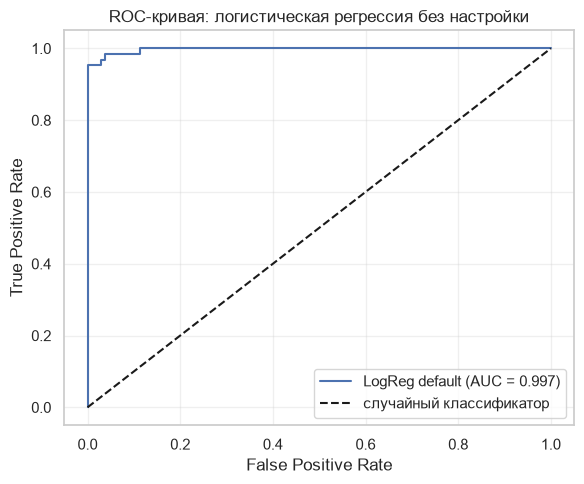

In [25]:
fpr_lr, tpr_lr, _ = roc_curve(y_test, y_proba_lr)

plt.figure(figsize=(6, 5))
plt.plot(fpr_lr, tpr_lr, label=f"LogReg default (AUC = {metrics_lr['roc_auc']:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="случайный классификатор")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC-кривая: логистическая регрессия без настройки")
plt.legend(loc="lower right")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

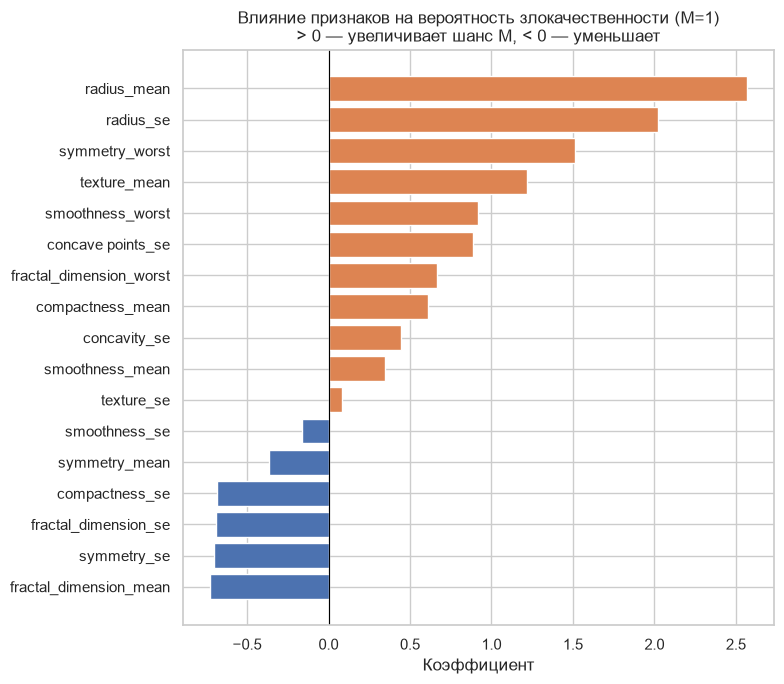

,coef
radius_mean,2.569029
radius_se,2.020933
symmetry_worst,1.509571
texture_mean,1.217252
smoothness_worst,0.916125
concave points_se,0.885796
fractal_dimension_mean,-0.727008
symmetry_se,-0.699941
fractal_dimension_se,-0.690494
compactness_se,-0.682199


In [26]:
coefs = pd.Series(lr.coef_[0], index=features_lr).sort_values()
colors = ["#DD8452" if c > 0 else "#4C72B0" for c in coefs]

plt.figure(figsize=(8, 7))
plt.barh(coefs.index, coefs.values, color=colors)
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Коэффициент")
plt.title("Влияние признаков на вероятность злокачественности (M=1)\n> 0 — увеличивает шанс M, < 0 — уменьшает")
plt.tight_layout()
plt.show()

coefs.sort_values(key=abs, ascending=False).head(10).to_frame("coef")

### 3. Настройка C через LogisticRegressionCV

In [ ]:
from sklearn.linear_model import LogisticRegressionCV

lr_cv = LogisticRegressionCV(
    Cs=10,
    cv=5,
    scoring="f1",
    random_state=42,
    max_iter=1000,
    l1_ratios=(0,),  # L2-регуляризация
    use_legacy_attributes=False,
)
lr_cv.fit(X_train_lr, y_train)

best_C = float(np.asarray(lr_cv.C_).ravel()[0])
print("Лучший C:", round(best_C, 4))
print("(для сравнения: default LogisticRegression использует C=1.0)")
# scores_: (n_folds, n_l1_ratios, n_Cs) при use_legacy_attributes=False
cv_f1_by_C = np.asarray(lr_cv.scores_).mean(axis=0)[0]

In [ ]:
# Средний CV F1 по сетке C
cs = np.asarray(lr_cv.Cs_).ravel()

plt.figure(figsize=(7, 4))
plt.semilogx(cs, cv_f1_by_C, marker="o")
plt.axvline(best_C, color="red", linestyle="--", label=f"best C = {best_C:.3g}")
plt.axvline(1.0, color="gray", linestyle=":", label="default C = 1")
plt.xlabel("C (чем меньше — тем сильнее регуляризация)")
plt.ylabel("mean CV F1")
plt.title("Подбор C на 5-fold CV")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
y_pred_lrcv = lr_cv.predict(X_test_lr)
y_proba_lrcv = lr_cv.predict_proba(X_test_lr)[:, 1]

metrics_lrcv = {
    "accuracy": accuracy_score(y_test, y_pred_lrcv),
    "precision": precision_score(y_test, y_pred_lrcv),
    "recall": recall_score(y_test, y_pred_lrcv),
    "f1_score": f1_score(y_test, y_pred_lrcv),
    "roc_auc": roc_auc_score(y_test, y_proba_lrcv),
}

comparison_lr = pd.DataFrame(
    {
        "LogReg default (C=1)": metrics_lr,
        f"LogRegCV (C={best_C:.3g})": metrics_lrcv,
        "kNN tuned": metrics_tuned,
    }
).T
comparison_lr.round(4)

In [ ]:
fpr_lrcv, tpr_lrcv, _ = roc_curve(y_test, y_proba_lrcv)

plt.figure(figsize=(6, 5))
plt.plot(fpr_lr, tpr_lr, label=f"LogReg C=1 (AUC = {metrics_lr['roc_auc']:.3f})")
plt.plot(
    fpr_lrcv,
    tpr_lrcv,
    linestyle="--",
    label=f"LogRegCV C={best_C:.3g} (AUC = {metrics_lrcv['roc_auc']:.3f})",
)
plt.plot(fpr, tpr, linestyle=":", label=f"kNN (AUC = {metrics_tuned['roc_auc']:.3f})")
plt.plot([0, 1], [0, 1], "k--", alpha=0.5)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC: LogReg default vs LogRegCV vs kNN")
plt.legend(loc="lower right")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
coefs_cv = pd.Series(lr_cv.coef_[0], index=features_lr).sort_values()
coefs_default = pd.Series(lr.coef_[0], index=features_lr).reindex(coefs_cv.index)

fig, axes = plt.subplots(1, 2, figsize=(14, 7), sharey=True)

for ax, series, title in [
    (axes[0], coefs_default, "LogReg default (C=1)"),
    (axes[1], coefs_cv, f"LogRegCV (C={best_C:.3g})"),
]:
    colors = ["#DD8452" if c > 0 else "#4C72B0" for c in series]
    ax.barh(series.index, series.values, color=colors)
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_title(title)
    ax.set_xlabel("Коэффициент")

fig.suptitle("Влияние признаков: сильнее регуляризация → коэффициенты ближе к нулю", y=1.02)
plt.tight_layout()
plt.show()

pd.DataFrame({"coef_C=1": coefs_default, f"coef_C={best_C:.3g}": coefs_cv}).assign(
    abs_shrunk=lambda d: d.iloc[:, 0].abs() - d.iloc[:, 1].abs()
).sort_values("abs_shrunk", ascending=False).head(10)

**Выводы**

1. **CV выбрал C ≈ 0.36 < 1** — модель чуть сильнее регуляризована, чем «из коробки». Коэффициенты сжались к нулю, но **ранг важности почти тот же**: главные драйверы злокачественности — `radius_mean`, `radius_se`, `symmetry_worst`, `texture_mean` (размер и неоднородность).
2. **На этом test-сплите** F1/recall у LogRegCV чуть ниже, чем у default (регуляризация иногда «перестраховывается»), а **ROC-AUC остаётся ≈ 0.997** — качество ранжирования не просело.
3. **kNN vs логистическая регрессия:** лучше оказалась **логистическая регрессия** (выше accuracy, recall, F1 и AUC). kNN тоже силён (AUC ≈ 0.99), но LogReg даёт интерпретируемые веса и чуть более уверенное разделение классов.
4. Интересный момент: после удаления мультиколлинеарности (`|r| > 0.85`) модель опирается на «представителей» групп признаков — например, остаётся `radius_mean`, а не дублирующие `perimeter`/`area`.